# Week 18: From next-character likelihood to causal wake decoding

Why must parallel next-token training hide future inputs, even when deployment is autoregressive?

**Prerequisites:** Week 17 mechanics; cross-entropy and MSE. This is a required language-model laboratory.

Allow 120 minutes for the guided lab; estimate 3–5 hours total with reading and written analysis. This planning estimate has not been measured in a student pilot. Student edition: worked examples run immediately; set RUN_EXERCISES=True after completing the four functions. Incomplete tasks are reported, never counted as passes.

## Laboratory route and reading map

| Notebook stage | Input/output | Required observation |
|---|---|---|
| Character-model fit | Integer context IDs to logits at every position | Training loss and whole-validation-document NLL; vocabulary excludes validation-only characters |
| POD prefix perturbation | Four continuous rank-eight state vectors to four shifted targets | Earlier masked outputs stay fixed when future inputs change |
| Tasks 1–2 | Stride-one windows and log-softmax likelihood | Check one batch and a hand-computed NLL before using perplexity |
| Tasks 3–4 | Prefix invariance and per-position likelihood | A final-position success must not conceal errors at earlier positions |

Change LM_STEPS, MODEL_WIDTH, CONTEXT or SAMPLE_TEMPERATURE one at a time. Width must remain divisible by four attention heads. Temperature changes sampling rather than fitted weights. The 160-update default is a small CPU teaching fit; generated prose is unvalidated. The POD masked/unmasked curves below come from the same randomly initialized decoder and the same perturbed input, so the experiment isolates information access rather than comparing trained forecast accuracy.

In [1]:
from pathlib import Path
import sys, os, subprocess, importlib.util
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'flowmllab/transformer_course.py').exists()), None)
try:
    _in_colab = importlib.util.find_spec("google.colab") is not None
except (ModuleNotFoundError, ValueError):
    _in_colab = False
if _in_colab:
    _course_target = ROOT if ROOT is not None else Path("/content/FlowMLLab")
    if not _course_target.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none",
                        "--sparse", "https://github.com/Ehsan-Roohi/FlowMLLab.git",
                        str(_course_target)], check=True)
    _course_complete = all((_course_target / p).exists() for p in ['flowmllab/transformer_course.py', 'flowmllab', 'course/lessons', 'data/modal_labs', 'results/transformer_course_v3', 'results/transformer_sensor_ablation', 'notebooks/week07_3', 'notebooks/week07_4', 'docs', 'flowmllab/late_teaching_plots.py'])
    if not _course_complete and (_course_target / ".git").exists():
        _sparse = subprocess.run(["git", "-C", str(_course_target), "config", "--bool",
                                  "core.sparseCheckout"], capture_output=True, text=True, check=False)
        if _sparse.stdout.strip() != "true":
            raise RuntimeError("This full checkout is missing required lesson files; use a complete course checkout or a new Colab runtime.")
        # Add this lesson's dependencies; keep any previous sparse selection.
        subprocess.run(["git", "-C", str(_course_target), "sparse-checkout",
                        "add", *['flowmllab', 'course/lessons', 'data/modal_labs', 'results/transformer_course_v3', 'results/transformer_sensor_ablation', 'notebooks/week07_3', 'notebooks/week07_4', 'docs']], check=True)
    elif not _course_complete:
        raise RuntimeError("The extracted course folder is incomplete for this lesson. Use the complete portable bundle or a new Colab runtime.")
    ROOT = _course_target
if ROOT is None or not all((ROOT / p).exists() for p in ['flowmllab/transformer_course.py', 'flowmllab', 'course/lessons', 'data/modal_labs', 'results/transformer_course_v3', 'results/transformer_sensor_ablation', 'notebooks/week07_3', 'notebooks/week07_4', 'docs', 'flowmllab/late_teaching_plots.py']):
    raise RuntimeError("Open this notebook in a FlowMLLab checkout, or use its Open in Colab link and run this setup cell first.")
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Course checkout:", ROOT)

import tempfile, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from flowmllab import transformer_course as lab
lab.seed_all(17)
cases,input_manifest=lab.load_data(ROOT)
EVIDENCE=ROOT/"results/transformer_course_v3"
_student_parent=ROOT/"student_runs/transformer_labs"
_student_parent.mkdir(parents=True,exist_ok=True)
workspace=tempfile.TemporaryDirectory(prefix="classroom-",dir=_student_parent)
RUN_OUTPUT=Path(workspace.name)
task_status={}
print("Loaded checksummed native wake fields. Optional student work stays in:",RUN_OUTPUT)

task_status={i:None for i in range(1,5)}


Course checkout: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-late-lectures-20261121/cpu-repo


Loaded checksummed native wake fields. Optional student work stays in: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-late-lectures-20261121/cpu-repo/student_runs/transformer_labs/classroom-c3sawwf7


In [2]:
RUN_EXERCISES=False

## Train a small language model from scratch

Train a small character model on actual FlowMLLab documentation, with a separate document for validation. This is an instructional language model, not a pretrained LLM. Vocabulary is fitted on training documents only; unseen validation characters map to an explicit unknown token. Perplexity and generated text do not establish physical correctness.

Architecture walkthrough: integer IDs [B,24] enter a learned vocabulary embedding [V,24], then 24 learned position vectors are added. One pre-normalized Block forms Q/K/V [B,4,24,6], blocks future keys, concatenates four heads, and adds the attention residual; a normalized 24→48→24 GELU feed-forward path adds a second residual. The output projection maps each token to V logits. Cross-entropy predicts the next character at every position. Trace one batch with print(language) and report each dimension. This discrete-token language experiment is distinct from the continuous POD regression experiment below.

Corpus provenance: [('data/modal_labs/README.md', 'f14f4d43254aa647eb2ebdab9f2ebe042a49b35f16bfa60dd2448e3d0a5d695b'), ('docs/RESULTS_GUIDE.md', 'be79138354cfd3fe483823947169cad4e97bab8aad9fce4fb95c07bc35fe742d'), ('notebooks/week07_3/README.md', '6e611884bfed75feb41e88850fe175b7d02edc664cb372bb075c8169edbf205f'), ('notebooks/week07_4/README.md', '314df7e5450b59f55580f6271524fe93991f8527ba2db0cbdac5e1c72164696e')]
Training/validation characters: 53171 616 windows: 13287 148
Validation unknown-token fraction: 0.0


Evaluated validation windows/tokens: 148 3552
Vocabulary: 72 held-out cross-entropy: 2.73158869013056 perplexity: 15.357265586054938
Validation uses a separate course document; shared domain and short context limit generalization claims.
Sample: the ainid ndyr d
#ce `-esmindall  [*; conguprnotiout mud aiohedialesurer eele-s poure prbo trelorer t ou


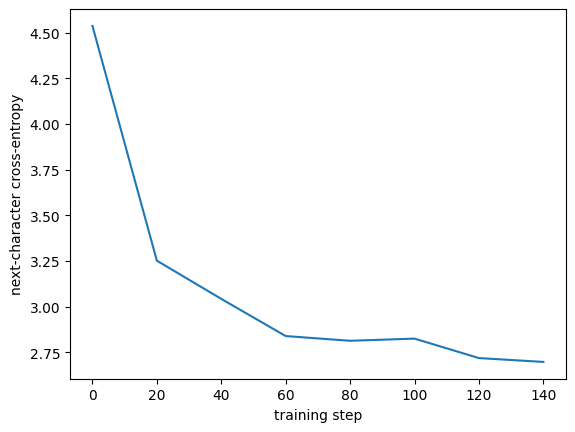

In [3]:
LM_STEPS=160
MODEL_WIDTH=24
CONTEXT=24
SAMPLE_TEMPERATURE=.8
assert MODEL_WIDTH%4==0 and CONTEXT>1 and SAMPLE_TEMPERATURE>0
train_paths=[ROOT/'data/modal_labs/README.md',ROOT/'docs/RESULTS_GUIDE.md',ROOT/'notebooks/week07_3/README.md']
validation_path=ROOT/'notebooks/week07_4/README.md'
text='\n'.join(p.read_text(encoding='utf-8').lower() for p in train_paths)
validation_text=validation_path.read_text(encoding='utf-8').lower()
vocab=sorted(set(text))+['?UNK?'];stoi={c:i for i,c in enumerate(vocab)};unknown=len(vocab)-1
ids_text=np.array([stoi[c] for c in text]);validation_ids=np.array([stoi.get(c,unknown) for c in validation_text]);context=CONTEXT
print('Corpus provenance:',[(p.relative_to(ROOT).as_posix(),lab.canonical_digest(p)) for p in train_paths+[validation_path]])
def text_windows(a):
    starts=np.arange(0,len(a)-context,4)
    return torch.tensor(np.stack([a[s:s+context] for s in starts])),torch.tensor(np.stack([a[s+1:s+context+1] for s in starts]))
tx,ty=text_windows(ids_text);vx,vy=text_windows(validation_ids)
print('Training/validation characters:',len(text),len(validation_text),'windows:',len(tx),len(vx))
print('Validation unknown-token fraction:',float(np.mean(validation_ids==unknown)))
language=lab.TinyLM(len(vocab),context,width=MODEL_WIDTH);opt=torch.optim.Adam(language.parameters(),lr=.004)
curve=[]
for step in range(LM_STEPS):
    batch=torch.randint(len(tx),(32,));opt.zero_grad()
    logits=language(tx[batch]);loss=torch.nn.functional.cross_entropy(logits.reshape(-1,len(vocab)),ty[batch].reshape(-1));loss.backward();opt.step()
    if step%20==0:curve.append((step,float(loss.detach())))
def full_validation_ce(model,x,y,batch_size=64):
    model.eval();total=0.;tokens=0
    with torch.no_grad():
        for start in range(0,len(x),batch_size):
            target=y[start:start+batch_size]
            logits=model(x[start:start+batch_size])
            total+=float(torch.nn.functional.cross_entropy(logits.reshape(-1,logits.shape[-1]),target.reshape(-1),reduction='sum'))
            tokens+=target.numel()
    if tokens==0:raise ValueError('empty validation set')
    return total/tokens,tokens
heldout,validation_tokens=full_validation_ce(language,vx,vy)
assert np.isclose(heldout,full_validation_ce(language,vx,vy,17)[0],rtol=1e-6)
print('Evaluated validation windows/tokens:',len(vx),validation_tokens)
# Overlapping windows count repeated next-token predictions; this is window-weighted CE,
# not a unique-character document likelihood.
print('Vocabulary:',len(vocab),'held-out cross-entropy:',heldout,'perplexity:',np.exp(heldout))
print('Validation uses a separate course document; shared domain and short context limit generalization claims.')
sample=[stoi[c] for c in 'the ']
with torch.no_grad():
    for _ in range(100):
        logits=language(torch.tensor([sample[-context:]]))[:,-1]/SAMPLE_TEMPERATURE
        sample.append(int(torch.multinomial(logits.softmax(-1),1)))
print('Sample:', ''.join(vocab[i] for i in sample))
plt.plot(*np.array(curve).T);plt.xlabel('training step');plt.ylabel('next-character cross-entropy');plt.show()

## Expose the causal-mask mechanism on POD tokens

Every output position predicts its next state. Perturb future inputs while holding a prefix fixed. The masked prefix must stay unchanged; the unmasked control must react. A one-block, last-token-only predictor cannot demonstrate this mechanism.

In [4]:
representation=lab.Representation.fit(cases[110]['omega'][:160],8)
z=representation.encode(cases[110]['omega']);xx,yy=lab.sequence_windows(z[:160])
decoder=lab.CausalDecoder();x=torch.tensor(xx[:3],dtype=torch.float32);changed=x.clone();changed[:,2:]+=10
with torch.no_grad():
    masked=float((decoder(x)[:,:2]-decoder(changed)[:,:2]).abs().max())
    for block in decoder.blocks:block.causal=False
    unmasked=float((decoder(x)[:,:2]-decoder(changed)[:,:2]).abs().max())
print('Masked prefix change:',masked,'unmasked:',unmasked)
assert masked<1e-6 and unmasked>1e-3
for block in decoder.blocks:block.causal=True
print('Inputs:',xx.shape,'all-position shifted targets:',yy.shape)

Masked prefix change: 0.0 unmasked: 0.25055184960365295
Inputs: (156, 4, 8) all-position shifted targets: (156, 4, 8)


## Plot the controlled future-information test

Use the same decoder weights before and after perturbing future input positions. A zero prefix response confirms the masking dependency; it is not a claim of learned CFD accuracy.

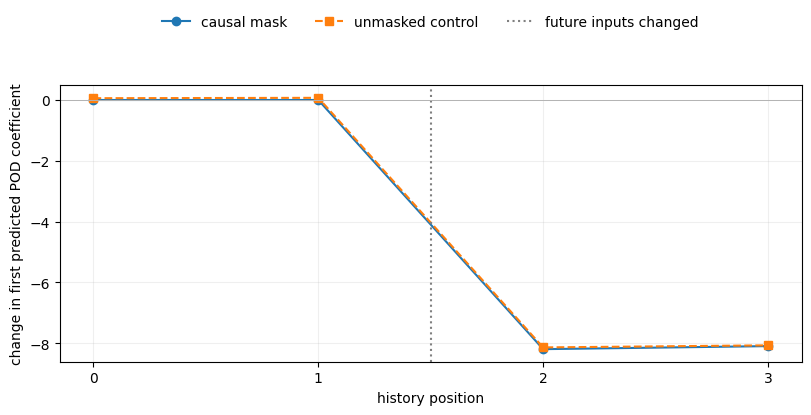

In [5]:
with torch.no_grad():
    masked_difference=(decoder(changed)-decoder(x))[0,:,0].numpy()
    for block in decoder.blocks:block.causal=False
    unmasked_difference=(decoder(changed)-decoder(x))[0,:,0].numpy()
    for block in decoder.blocks:block.causal=True
positions=np.arange(x.shape[1])
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
ax.plot(positions,masked_difference,"o-",label="causal mask")
ax.plot(positions,unmasked_difference,"s--",label="unmasked control")
ax.axvline(1.5,color=".5",ls=":",label="future inputs changed")
ax.axhline(0,color=".7",lw=.7)
ax.set(xlabel="history position",ylabel="change in first predicted POD coefficient")
ax.legend(loc="upper center",bbox_to_anchor=(.5,1.3),ncol=3,frameon=False)
ax.set_xticks(positions);ax.grid(alpha=.2)
plt.show()


## Task 1: Shift targets

Build next-character input/target windows without allowing a window to cross the provided sequence boundary.

Interface contract: Input a is a one-dimensional NumPy array, with 1<=k<len(a). Return a pair of arrays with shape [len(a)-k,k], including every stride-one window.

In [6]:
def shifted(a,k):
    """Input a is a one-dimensional NumPy array, with 1<=k<len(a). Return a pair of arrays with shape [len(a)-k,k], including every stride-one window."""
    raise NotImplementedError

In [7]:
if RUN_EXERCISES:
    try:
        for length,width in [(9,2),(13,5)]:
            sequence=np.arange(length)*3+2
            a,b=shifted(sequence,width)
            np.testing.assert_array_equal(a,np.array([sequence[i:i+width] for i in range(length-width)]))
            np.testing.assert_array_equal(b,np.array([sequence[i+1:i+width+1] for i in range(length-width)]))
        task_status[1]=True
    except NotImplementedError:
        task_status[1]=None
    except Exception as exc:
        task_status[1]=False
        print("Task 1 check failed:",type(exc).__name__,str(exc))
else:
    task_status[1]=None
print("Task 1:","PASS" if task_status[1] is True else "NOT SUBMITTED" if task_status[1] is None else "FAILED")

Task 1: NOT SUBMITTED


## Task 2: Cross-entropy and perplexity

Compute negative log likelihood from logits using log_softmax; average over all positions.

Interface contract: Inputs logits:[batch,time,vocabulary] and integer targets:[batch,time] are Torch tensors. Return one scalar Torch tensor containing mean natural-log NLL.

In [8]:
def sequence_nll(logits,targets):
    """Inputs logits:[batch,time,vocabulary] and integer targets:[batch,time] are Torch tensors. Return one scalar Torch tensor containing mean natural-log NLL."""
    raise NotImplementedError

In [9]:
if RUN_EXERCISES:
    try:
        example=torch.randn(2,4,7);target=torch.randint(7,(2,4))
        torch.testing.assert_close(sequence_nll(example,target),torch.nn.functional.cross_entropy(example.reshape(-1,7),target.reshape(-1)))
        for value in (0.,2.):
            logits=torch.full((3,5,4),value)
            targets=torch.zeros(3,5,dtype=torch.long)
            assert np.isclose(float(sequence_nll(logits,targets)),np.log(4))
        task_status[2]=True
    except NotImplementedError:
        task_status[2]=None
    except Exception as exc:
        task_status[2]=False
        print("Task 2 check failed:",type(exc).__name__,str(exc))
else:
    task_status[2]=None
print("Task 2:","PASS" if task_status[2] is True else "NOT SUBMITTED" if task_status[2] is None else "FAILED")

Task 2: NOT SUBMITTED


## Task 3: Causal prefix invariant

Return whether future perturbation leaves the prefix unchanged. Test both the masked model and its deliberately broken control.

Interface contract: model returns a [batch,time,feature] tensor and is already in evaluation mode. x has that shape; 0<prefix<time. Add 10 to all future input positions, hold the prefix fixed, and return a Python bool comparing every prefix output at atol=1e-6.

In [10]:
def prefix_is_invariant(model,x,prefix):
    """model returns a [batch,time,feature] tensor and is already in evaluation mode. x has that shape; 0<prefix<time. Add 10 to all future input positions, hold the prefix fixed, and return a Python bool comparing every prefix output at atol=1e-6."""
    raise NotImplementedError

In [11]:
if RUN_EXERCISES:
    try:
        assert prefix_is_invariant(decoder,x,2)
        for block in decoder.blocks:block.causal=False
        assert not prefix_is_invariant(decoder,x,2)
        for block in decoder.blocks:block.causal=True
        task_status[3]=True
    except NotImplementedError:
        task_status[3]=None
    except Exception as exc:
        task_status[3]=False
        print("Task 3 check failed:",type(exc).__name__,str(exc))
else:
    task_status[3]=None
print("Task 3:","PASS" if task_status[3] is True else "NOT SUBMITTED" if task_status[3] is None else "FAILED")

Task 3: NOT SUBMITTED


## Task 4: Evaluate a language model by position

Return per-position negative log likelihood, token accuracy, overall NLL and perplexity for [batch,time,vocabulary] logits. Validate dimensions and targets. Compare a correct predictor with one that is correct only at the final position; report why final-token accuracy can hide training failures.

Interface contract: Return a dictionary with position_nll and position_accuracy as length-time Torch tensors averaged over batch, nll and perplexity as Python floats averaged over all tokens. Use natural logs. Non-3-D logits, mismatched target shape, empty targets or tokens outside [0,vocabulary) must raise ValueError. Targets are integer token IDs.

In [12]:
def language_metrics(logits,targets):
    """Return a dictionary with position_nll and position_accuracy as length-time Torch tensors averaged over batch, nll and perplexity as Python floats averaged over all tokens. Use natural logs. Non-3-D logits, mismatched target shape, empty targets or tokens outside [0,vocabulary) must raise ValueError. Targets are integer token IDs."""
    raise NotImplementedError

In [13]:
if RUN_EXERCISES:
    try:
        for vocab in (3,7):
            logits=torch.zeros(2,4,vocab);targets=torch.zeros(2,4,dtype=torch.long)
            result=language_metrics(logits,targets)
            assert np.isclose(result['perplexity'],vocab)
            torch.testing.assert_close(result['position_nll'],torch.full((4,),float(np.log(vocab))))
            logits[:,:-1,1]=5;logits[:,-1,0]=5
            result=language_metrics(logits,targets)
            assert result['position_accuracy'][-1]==1 and (result['position_accuracy'][:-1]==0).all()
            assert result['position_nll'][0]>result['position_nll'][-1]+4
        try:
            language_metrics(torch.zeros(2,3,4),torch.zeros(2,4,dtype=torch.long))
            raise AssertionError('shape mismatch accepted')
        except ValueError:pass
        task_status[4]=True
    except NotImplementedError:
        task_status[4]=None
    except Exception as exc:
        task_status[4]=False
        print("Task 4 check failed:",type(exc).__name__,str(exc))
else:
    task_status[4]=None
print("Task 4:","PASS" if task_status[4] is True else "NOT SUBMITTED" if task_status[4] is None else "FAILED")

Task 4: NOT SUBMITTED


## Assessment: 100 points

Coding Tasks 1–4: [5, 5, 5, 25] points; derivation 25, interpretation 25, reproducibility 10. Automated checks assess only coding behavior.

Derive: trace a 4-head causal Block and shifted targets.

Worked interpretation: Masking blocks access to future tokens; the poisoned-prefix test establishes a dependency property, not forecast accuracy. Window CE covers every validation window and includes repeated characters.

Reject and explain: “Low character perplexity proves a stable CFD rollout.”

An accurate numerical observation without its split, representation, or causal limitation earns at most half of interpretation points. Instructor marking and a timed student pilot are still required; automated checks establish interface/behavior only.



## Interpretation and submission

Submit the four completed functions, the requested plots/tables, and a 300-word claim ledger. Distinguish observations, fitted quantities, independent evaluation and unsupported extrapolation. Retain failed seeds. Use the lecture source for the rubric and assumptions.

In [14]:
print("Coding tasks passed:",sum(v is True for v in task_status.values()),"/",len(task_status))
workspace.cleanup()

Coding tasks passed: 0 / 4
